<a href="https://colab.research.google.com/github/Melyssa-Souza/Fashion-mnist-rnn-classifier/blob/main/RNN_Roupas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação com RNN usando Fashion MNIST (Classes Generalizadas)

## A importância dos tensores
Colocamos nossos dados em formato de tensores para poder passarmos para as redes neurais.

Qualquer forma de dados na biblioteca TensorFlow é representada pela estrutura de tensores, que são simplesmente arrays ou listas com n eixos. Em termos de álgebra linear, tensores são generalizações de matrizes. Por exemplo, um vetor é um tensor com uma dimensão ou um eixo. Uma matriz é um tensor com duas dimensões ou dois eixos. Uma pilha de matrizes é um tensor com 3 dimensões ou três eixos e assim por diante. É preciso ter cuidado para não confundir dimensões de um tensor – o número de eixos da estrutura de dados – com dimensão dos dados – o número de colunas ou variáveis em uma tabela de dados.

Os tensores tem tipos estáticos e todos os elementos devem ser do mesmo tipo. Eles também tem formato dinâmico, o que quer dizer que podemos reformatá-lo com operações de reshape, transpose, etc. Para representar o formato do tensor, usamos a notação entre colchetes [ ]. Assim, um tensor sem dimensão (um escalar) é representado pela forma [], um tensor 1D (vetor) é representado pela forma [k], um tensor 2D é representado pela forma [k,m] e assim por diante. Como um exemplo mais concreto, considera um lote de 100 imagens coloridas (RGB) e de tamanho 28x28 px. O tensor que armazenaria esses dados seria do formato [n_lote, n_altura, n_largura, n_cores], ou, em números, [100, 28, 28, 3].


[Referência: Aprenda TensorFlow, o pacote criado pelo Google para treinar redes neurais.
](https://matheusfacure.github.io/2017/05/12/tensorflow-essencial/)

## Mãos na massa

In [ ]:
# TensorFlow e tf.keras
import tensorflow as tf
from tensorflow import keras

# Bibliotecas Auxiliares
import numpy as np
import matplotlib.pyplot as plt

print(tf.__version__)

2.18.0


Precisamos do tensorflow para utilizar os tensores e o keras do tensoflow para poder criar as RNN.

Para esse problema vamos usar a base de dados Fashion MNIST que contém 70,000 imagens em tons de cinza em 10 categorias. As imagens mostram artigos individuais de roupas com baixa resolução (28 por 28 pixels). As imagens são arrays NumPy de 28x28, com os valores de pixels entre 0 à 255. As labels (alvo da classificação) são um array de inteiros, no intervalo de 0 a 9. Esse corresponde com a classe de roupa que cada imagem representa:



In [ ]:
fashion_mnist = keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
# Classes generalizadas por região do corpo
generalized_class_names = ['chestwear', 'legwear', 'chestwear', 'fullbodywear', 'chestwear','footwear', 'chestwear', 'footwear', 'accessory', 'footwear']

In [ ]:
train_images.shape

len(train_labels)

train_labels

test_images.shape

(10000, 28, 28)

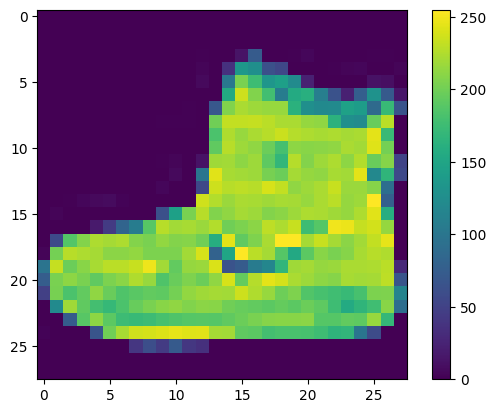

In [ ]:
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

Os valores dos pixels da imagem estão entre 0 e 255. Escalaremos esses valores no intervalo de 0 e 1. É importante lembrar que o conjunto de treinamento e o conjunto de teste devem ser processados do mesmo modo.

In [ ]:
train_images = train_images / 255.0
test_images = test_images / 255.0

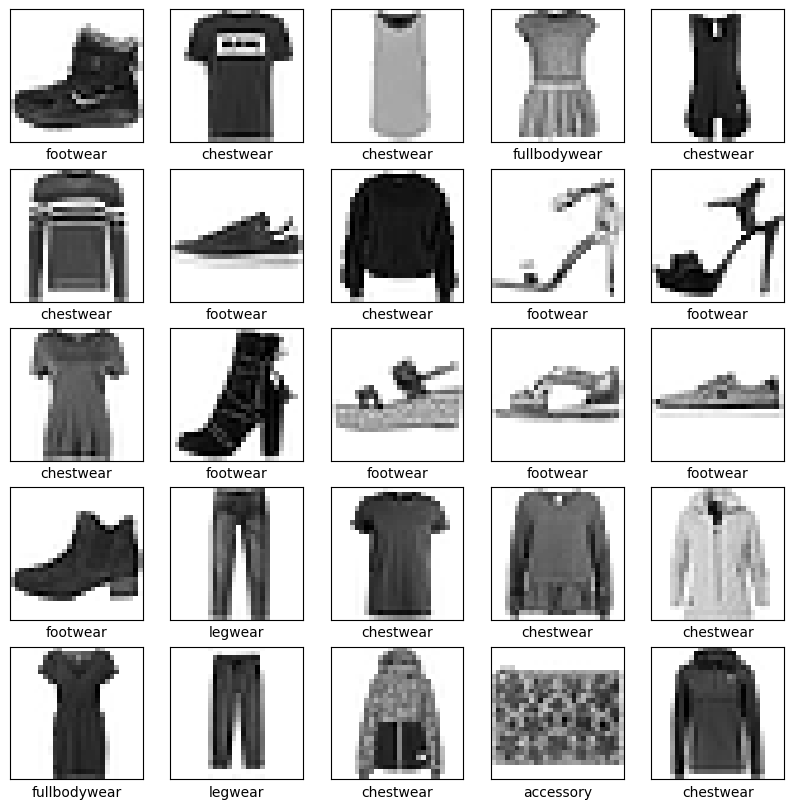

In [ ]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1) #Adicione um eixo à figura atual ou recupere um eixo existente.
    plt.xticks([]) #Obtenha ou defina os locais e rótulos atuais dos ticks do eixo x.
    plt.yticks([]) #Obtenha ou defina os locais e rótulos atuais dos ticks do eixo y.
    plt.grid(False) #Configure as linhas de grade.
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(generalized_class_names[train_labels[i]])
plt.show()

### Construindo as camadas

tf.keras.layers.Flatten: Nessa camada reformatamos os dados, já que estamos lidando com imagens. Ela transforma o formato da imagem de um array de imagens de duas dimensões (of 28 by 28 pixels) para um array de uma dimensão (de 28 * 28 = 784 pixels).

As outras duas camadas tf.keras.layers.Dense,  são camadas neurais densely connected, ou fully connected. A primeira camada Dense tem 128 nós(ou neurônios). A segunda (e última) camada é uma softmax de 10 nós que retorna um array de 10 probabilidades, cuja soma resulta em 1. Cada nó contém um valor que indica a probabilidade de que aquela imagem pertence a uma das 10 classes.

In [ ]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

### Compilando o modelo

Além de definir as camadas precisamos definir qual será a função de otimização, a função de perda e a métrica de avaliação. A cada loop que realizamos um valor de perda é calculado, esse valor é calculado pela função de loss. Tendo esse valor da perda, a função de otimização vai retornar uma saída a fim de melhorar o modelo. E dentro desse processo de calcular perda, também usamos uma métrica que possa dizer o quanto o nosso modelo está bom naquela iteração, que no nosso caso utilizaremos a acurácia.

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

### Treinando o modelo

Para treinar o modelo passaremos os dados de entrada e saída. Além disso, definimos a quantidade de épocas, que é quantas vezes nosso modelo será treinado.

In [ ]:
history = model.fit(train_images, train_labels, epochs=20, validation_data=(test_images, test_labels))

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.7820 - loss: 0.6274 - val_accuracy: 0.8449 - val_loss: 0.4461
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8623 - loss: 0.3822 - val_accuracy: 0.8626 - val_loss: 0.3839
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8780 - loss: 0.3342 - val_accuracy: 0.8641 - val_loss: 0.3755
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8871 - loss: 0.3079 - val_accuracy: 0.8591 - val_loss: 0.4072
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8900 - loss: 0.3001 - val_accuracy: 0.8494 - val_loss: 0.4126
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8966 - loss: 0.2798 - val_accuracy: 0.8743 - val_loss: 0.3621
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9027 - loss: 0.2665 - val_accuracy: 0.8712 - val_loss: 0.3696
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9060 - loss: 0.25

Repare que em cada iteração temos um valor da loss e o valor da acurácia.

In [ ]:
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

print('\nTest accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8847 - loss: 0.3620

Test accuracy: 0.8847000002861023


### Predição

Agora vamos usar nosso modelo para fazer predições.

In [ ]:
predictions = model.predict(test_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


Na camada de saída usamos a softmax, que retorna a probabilidade de cada classificação. Na célula a seguir podemos ver a probabilidade da imagem pertencer a cada classe.

In [ ]:
predictions[0]

array([7.7231846e-11, 2.2340995e-14, 2.6203400e-14, 2.3878352e-11,
       1.5403965e-12, 3.2791999e-07, 1.1356721e-08, 7.0801110e-04,
       2.6952949e-11, 9.9929166e-01], dtype=float32)

Podemos pegar esse array e retornar o maior valor, para ver como a imagem foi classificada pelo nosso modelo.

In [ ]:
np.argmax(predictions[0])

np.int64(9)

In [ ]:
test_labels[0]

np.uint8(9)

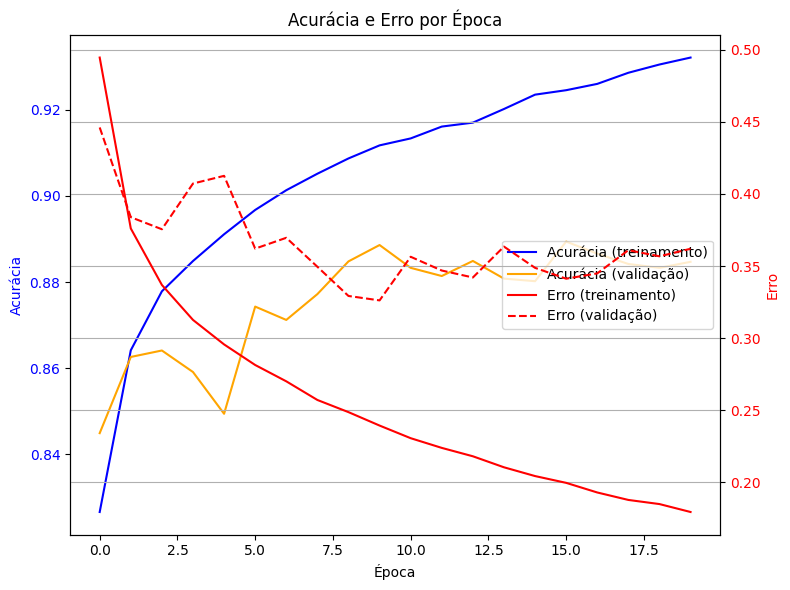

In [ ]:

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

fig, ax1 = plt.subplots(figsize=(8, 6))

# Eixo Y da esquerda — acurácia
ax1.set_title('Acurácia e Erro por Época')
ax1.set_xlabel('Época')
ax1.set_ylabel('Acurácia', color='blue')
ax1.plot(epochs_range, acc, color='blue', label='Acurácia (treinamento)')
ax1.plot(epochs_range, val_acc, color='orange', label='Acurácia (validação)')
ax1.tick_params(axis='y', labelcolor='blue')

# Eixo Y da direita — perda
ax2 = ax1.twinx()
ax2.set_ylabel('Erro', color='red')
ax2.plot(epochs_range, loss, color='red', linestyle='-', label='Erro (treinamento)')
ax2.plot(epochs_range, val_loss, color='red', linestyle='--', label='Erro (validação)')
ax2.tick_params(axis='y', labelcolor='red')

# Combinar legendas
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.tight_layout()
plt.grid(True)
plt.show()


A linha de "Validação" mostra se o modelo consegue generalizar para novos dados (evita overfitting).

Por que usar validação?
Para saber quando parar de treinar (early stopping).

Para comparar diferentes modelos de forma justa.

Para evitar um modelo que apenas "decorou" os dados.